# DepositIQ 03 — Exploratory Data Analysis

**Rubric:** Criterion 4 — EDA · **Tasks:** T16–T18 · **Phase:** 4
**Dataset:** `data/processed/train.csv` — the **training half only**, 36,168 × 19, loaded through
[src/split.py](../src/split.py)
**Depends on:** T15 ([src/split.py](../src/split.py)) for the fixed, stratified split, and T12
([src/clean.py](../src/clean.py)) for the cleaned frame underneath it.

## What this notebook does

T15 froze the evaluation halves. This notebook reads **only the training one** and starts the EDA:

- **§1 Target distribution and class imbalance** (T16) — how many clients subscribed, how lopsided
  the class balance is, and which evaluation baselines that distribution *forces* on the rest of the
  project.
- **§2 Numeric distributions and skew** (T17) — the eight numeric columns, one interpretation line
  each, and the traps their shapes set for scaling.
- **§3 Categorical features vs subscription rate** (T18) — all 44 levels of the nine `object` columns
  against the base rate, with the best and worst segments named.

Sections **§4–§5 are reserved for T19–T20** (campaign features, correlation) so that the EDA lands as
one notebook with figure numbers `01_`–`05_` rather than five files.

## Why the training half only

The test half must stay unseen until T32, or it stops being a held-out test. Everything below is
measured on `train.csv`; the one place the source population appears is the split-sanity line in §1.5,
which quotes the **label rate only** that T15 already published — no test features are touched, and
`test.csv` is not read anywhere in this notebook.

## Two decisions this section already answers

1. **D04 — accuracy is not a headline metric.** §1.3 quantifies the trivial classifier that exploits
   the imbalance and shows what it scores.
2. **D15 — the honest baselines.** PR-AUC is read against the *positive rate*, not 0.5; ROC-AUC
   against 0.5.

## Setup

Same path handling as T11/T13 (decision D12), so the notebook runs from any working directory. The
training half is loaded through `split.load_split` rather than a bare `read_csv`, so there is one
place that knows how these files are read — and the load is asserted to be `train.csv`, not the test
file.

In [1]:
import platform
import sys
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold


def find_repo_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "src" / "config.py").exists():
            return candidate
    raise RuntimeError("Could not find the repository root above " + str(start))


REPO_ROOT = find_repo_root(Path.cwd())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src import config                  # noqa: E402
from src import data_loader as load     # noqa: E402
from src import split                   # noqa: E402

config.ensure_dirs()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
sns.set_theme(style="whitegrid")

TRAIN_PATH = config.TRAIN_CSV
TRAIN = split.load_split("full", "train")

# Provenance guard: this notebook must be looking at the training half, and it must be the file
# T15 wrote. The test half is deliberately not loaded anywhere in this notebook.
assert TRAIN_PATH == split.SPLITS["full"][0], "this notebook must read the train split, not the test"
assert TRAIN_PATH.name == "train.csv"
assert config.TEST_CSV.name not in TRAIN_PATH.name

print("Executed  :", datetime.now().strftime("%Y-%m-%d %H:%M:%S"))
print("Python    :", platform.python_version())
print("Source    :", TRAIN_PATH.relative_to(REPO_ROOT), "->", tuple(TRAIN.shape))
print("Test file :", config.TEST_CSV.name, "not read by this notebook (held out until T32)")

Executed  : 2026-10-28 19:50:18
Python    : 3.11.9
Source    : data\processed\train.csv -> (36168, 19)
Test file : test.csv not read by this notebook (held out until T32)


## 1. Target distribution and class imbalance (T16)

The target is `y`: `yes` = the client subscribed to a term deposit. The first question of any
classification project is simply *how many of each class are there*, because that single number
decides what counts as a good model.

In [2]:
counts = TRAIN[config.TARGET].value_counts()
order = [config.NEGATIVE_LABEL, config.POSITIVE_LABEL]          # no first, yes second
counts = counts.reindex(order)

n_total = int(counts.sum())
n_yes = int(counts[config.POSITIVE_LABEL])
n_no = int(counts[config.NEGATIVE_LABEL])
rate = n_yes / n_total
imbalance_ratio = n_no / n_yes

summary = pd.DataFrame({
    "class": [f"{config.NEGATIVE_LABEL}  (did not subscribe)", f"{config.POSITIVE_LABEL}  (subscribed)"],
    "count": [n_no, n_yes],
    "share": [n_no / n_total, n_yes / n_total],
})
summary["cumulative"] = summary["share"].cumsum().values

print(f"training half : {TRAIN_PATH.name}  ({n_total:,} rows)")
print()
print(summary.to_string(index=False, formatters={"share": "{:.4%}".format, "cumulative": "{:.4%}".format}))
print()
print(f"positive rate : {n_yes:,} / {n_total:,} = {rate:.4%}")
print(f"imbalance     : {n_no:,} : {n_yes:,} = {imbalance_ratio:.2f} : 1")
print(f"majority class: {n_no / n_total:.4%} of the half -> the trivial 'always no' score")

training half : train.csv  (36,168 rows)

                  class  count    share cumulative
no  (did not subscribe)  31937 88.3018%   88.3018%
      yes  (subscribed)   4231 11.6982%  100.0000%

positive rate : 4,231 / 36,168 = 11.6982%
imbalance     : 31,937 : 4,231 = 7.55 : 1
majority class: 88.3018% of the half -> the trivial 'always no' score


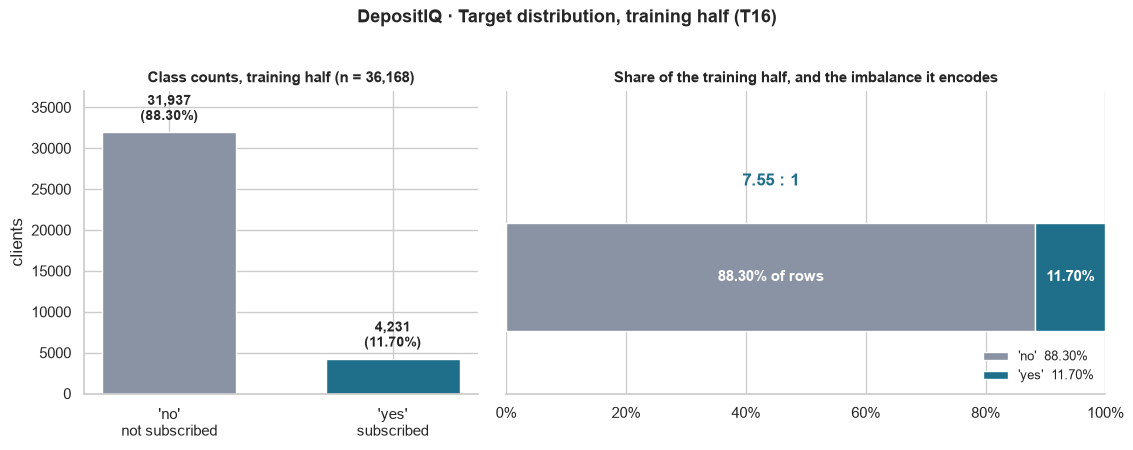

saved: reports\figures\01_target_distribution.png


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4), gridspec_kw={"width_ratios": [1.05, 1.6]})
palette = {config.NEGATIVE_LABEL: "#8a93a3", config.POSITIVE_LABEL: "#1f6f8b"}

# Panel A - raw counts. The minority bar is the whole point of the figure.
ax = axes[0]
bars = ax.bar([f"'{config.NEGATIVE_LABEL}'\nnot subscribed", f"'{config.POSITIVE_LABEL}'\nsubscribed"],
              [n_no, n_yes], color=[palette[config.NEGATIVE_LABEL], palette[config.POSITIVE_LABEL]],
              width=0.6)
for bar, value, share in zip(bars, [n_no, n_yes], [n_no / n_total, n_yes / n_total]):
    ax.annotate(f"{value:,}\n({share:.2%})",
                xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                xytext=(0, 6), textcoords="offset points",
                ha="center", va="bottom", fontsize=10, weight="bold")
ax.set_ylim(0, n_no * 1.16)
ax.set_ylabel("clients")
ax.set_title(f"Class counts, training half (n = {n_total:,})", fontsize=11, weight="bold")
ax.spines[["top", "right"]].set_visible(False)

# Panel B - the same data as shares, with the ratio that governs evaluation.
ax = axes[1]
ax.barh([0], [n_no / n_total], color=palette[config.NEGATIVE_LABEL], height=0.42,
        label=f"'{config.NEGATIVE_LABEL}'  {n_no / n_total:.2%}")
ax.barh([0], [n_yes / n_total], left=[n_no / n_total], color=palette[config.POSITIVE_LABEL], height=0.42,
        label=f"'{config.POSITIVE_LABEL}'  {n_yes / n_total:.2%}")
ax.annotate(f"{n_no / n_total:.2%} of rows", xy=(n_no / n_total / 2, 0), ha="center", va="center",
            color="white", fontsize=11, weight="bold")
ax.annotate(f"{n_yes / n_total:.2%}", xy=(n_no / n_total + n_yes / n_total / 2, 0), ha="center", va="center",
            color="white", fontsize=11, weight="bold")
ax.annotate(f"{imbalance_ratio:.2f} : 1", xy=(n_no / n_total / 2, 0.34), ha="center", va="bottom",
            fontsize=12, weight="bold", color="#1f6f8b")
ax.set_xlim(0, 1)
ax.set_ylim(-0.45, 0.72)
ax.set_yticks([])
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_title("Share of the training half, and the imbalance it encodes", fontsize=11, weight="bold")
ax.spines[["top", "right", "left"]].set_visible(False)
ax.legend(loc="lower right", frameon=False, fontsize=9)

fig.suptitle("DepositIQ · Target distribution, training half (T16)", fontsize=13, weight="bold", y=1.02)
fig.tight_layout()
figure_path = config.FIGURES_DIR / "01_target_distribution.png"
fig.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show()
print("saved:", figure_path.relative_to(REPO_ROOT))

> **Viva line for this figure:** *eleven point seven percent of the training half subscribed* — so
> a model that always answers "no" scores **88.3% accuracy** while producing nothing, which is
> exactly why this project reports **PR-AUC against a 0.117 random baseline** instead of accuracy
> (D04, D15).

### 1.1 What the distribution forces us to report

The imbalance is not a cosmetic detail: it sets the score a trivial model gets. Every number below is
derived from the counts above, so the evaluation section (T32–T35) cannot quietly drift away from
them.

In [4]:
trivial_always_no = n_no / n_total                 # predicts 'no' for everyone
pr_auc_random = rate                               # a random scorer's average precision == base rate
roc_auc_random = 0.5                               # a random scorer's ROC-AUC
per_call_yield = rate                              # expected subscriptions per call at random
calls_per_subscription = 1 / rate

baselines = pd.DataFrame([
    ["Accuracy, always predict 'no'", f"{trivial_always_no:.4%}", "0 (no subscriptions found)",
     "D04: why accuracy is not the headline"],
    ["Accuracy, always predict 'yes'", f"{rate:.4%}", "every client flagged",
     "the other degenerate classifier"],
    ["PR-AUC (average precision)", f"{pr_auc_random:.4%}", f"{pr_auc_random:.4f}",
     "D15: the value the model must beat"],
    ["ROC-AUC", "50.0000%", "0.5000", "D15: the other honest baseline"],
], columns=["metric", "trivial score", "what it means", "why it matters"])

print(baselines.to_string(index=False))
print()
print(f"At the base rate a random campaign yields {per_call_yield:.4%} subscriptions per call,")
print(f"i.e. about {calls_per_subscription:.2f} calls per subscription to reach one {config.POSITIVE_LABEL!r}.")

                        metric trivial score              what it means                        why it matters
 Accuracy, always predict 'no'      88.3018% 0 (no subscriptions found) D04: why accuracy is not the headline
Accuracy, always predict 'yes'      11.6982%       every client flagged       the other degenerate classifier
    PR-AUC (average precision)      11.6982%                     0.1170    D15: the value the model must beat
                       ROC-AUC      50.0000%                     0.5000        D15: the other honest baseline

At the base rate a random campaign yields 11.6982% subscriptions per call,
i.e. about 8.55 calls per subscription to reach one 'yes'.


### 1.2 Where the training half came from

T15's split was stratified (D26), so the training half should reproduce the source population's label
rate almost exactly. The population rate is quoted from the raw file through the loader — the **label
only**, which T15 already published; the held-out half's rows are not part of this section.

In [5]:
population = load.load_raw("full", verbose=False)
population_rate = float((population[config.TARGET] == config.POSITIVE_LABEL).mean())

delta = rate - population_rate
print(f"source population  : {len(population):,} rows, y == 'yes' {population_rate:.6%}")
print(f"training half      : {n_total:,} rows, y == 'yes' {rate:.6%}")
print(f"difference         : {delta * 100:+.6f} pp")
print()
print("Both are far inside the +/-1pp the split was graded on (T15), so the EDA below describes the")
print("same population as the raw file - the split did not distort the target.")

source population  : 45,211 rows, y == 'yes' 11.698480%
training half      : 36,168 rows, y == 'yes' 11.698186%
difference         : -0.000294 pp

Both are far inside the +/-1pp the split was graded on (T15), so the EDA below describes the
same population as the raw file - the split did not distort the target.


### 1.3 What the imbalance means for validation

The counts above also fix how the model can be validated: a fold-level metric is only as stable as
the number of positives that land in each fold. This is measured rather than assumed, because it is the
justification for the fold count T30 will use.


In [6]:
# How many positives each validation fold would hold under 5-fold stratified CV (T30's design).
n_folds = 5
skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=config.RANDOM_STATE)
fold_rows = []
for fold, (_, val_index) in enumerate(skf.split(TRAIN, TRAIN[config.TARGET]), start=1):
    fold_yes = int((TRAIN[config.TARGET].iloc[val_index] == config.POSITIVE_LABEL).sum())
    fold_rows.append({"fold": fold, "val rows": len(val_index), "positives": fold_yes,
                      "val rate": fold_yes / len(val_index)})
fold_table = pd.DataFrame(fold_rows)

print(f"{n_folds}-fold stratified CV over the training half ({n_total:,} rows)")
print(fold_table.to_string(index=False, formatters={"val rate": "{:.4%}".format}))
print()
print(f"Every validation fold carries at least {int(fold_table['positives'].min()):,} positives, so a")
print("fold-level metric rests on a denominator big enough to be stable - the measured reason T30")
print("uses 5 folds rather than 10 (10 would halve this denominator for no gain in precision).")

5-fold stratified CV over the training half (36,168 rows)
 fold  val rows  positives val rate
    1      7234        846 11.6948%
    2      7234        846 11.6948%
    3      7234        847 11.7086%
    4      7233        846 11.6964%
    5      7233        846 11.6964%

Every validation fold carries at least 846 positives, so a
fold-level metric rests on a denominator big enough to be stable - the measured reason T30
uses 5 folds rather than 10 (10 would halve this denominator for no gain in precision).


In [7]:
# Evidence: the numbers this section states must be the numbers the data gives.
assert len(TRAIN) == 36168, len(TRAIN)
assert n_yes == 4231 and n_no == 31937, (n_yes, n_no)
assert abs(rate - 0.1169819) < 1e-7, rate
assert round(imbalance_ratio, 2) == 7.55, imbalance_ratio
assert abs(trivial_always_no - 0.8830181) < 1e-7, trivial_always_no
assert abs(pr_auc_random - rate) < 1e-12 and roc_auc_random == 0.5
assert abs(per_call_yield - rate) < 1e-12 and abs(calls_per_subscription - 1 / rate) < 1e-12
assert set(TRAIN[config.TARGET].unique()) == {"no", "yes"}
assert TRAIN_PATH.name == "train.csv" and config.TEST_CSV.name not in TRAIN_PATH.name
assert abs(delta) < 0.0001, delta                      # stratified split reproduces the population
assert len(fold_table) == 5 and fold_table["positives"].sum() == n_yes
assert figure_path.exists() and figure_path.stat().st_size > 20_000
assert figure_path.name == "01_target_distribution.png"
print("evidence: 13 assertion lines pass")

evidence: 13 assertion lines pass


## 2. Numeric distributions and skew (T17)

Eight of the nineteen columns in the training half are numeric, and this section profiles every one of
them. The requirement is one **interpretation line per variable** — a sentence a reader can act on,
not a description of a histogram's outline — so each variable below is paired with the number that
makes its shape matter.

Every value is measured on the **training half** (36,168 rows), never on the full frame. D28 records
why, and §2.2 shows it was not a formality: `previous`'s skew differs from T13's full-frame figure by
more than three points, and `balance` has 765 fewer negative rows here than in the whole file.


In [8]:
# The numeric set is read from the data and then checked against the list T17 names, so a change in the
# cleaner (D23 added `days_since_contact`) cannot quietly leave a column unprofiled.
NUMERIC = TRAIN.select_dtypes(include=np.number).columns.tolist()
EXPECTED_NUMERIC = ["age", "balance", "day", "duration", "campaign", "pdays", "previous",
                    "days_since_contact"]
assert sorted(NUMERIC) == sorted(EXPECTED_NUMERIC), (NUMERIC, EXPECTED_NUMERIC)
# The target as 0/1, so the correlations quoted in §2.2 are point-biserial coefficients. The count is
# checked against §1 here, so the two sections cannot disagree about what the positive class is.
y = TRAIN[config.TARGET].astype(str).str.strip().str.lower().eq(config.POSITIVE_LABEL).astype(int)
assert int(y.sum()) == 4231, int(y.sum())
print(f"numeric columns ({len(NUMERIC)}): {', '.join(NUMERIC)}")
print()


def describe(series: pd.Series) -> dict:
    """Every figure §2.1 and §2.2 quote, computed once from the training half."""
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    return {"n": int(series.notna().sum()), "missing": int(series.isna().sum()),
            "zeros": float((series == 0).mean()), "negative": int((series < 0).sum()),
            "min": series.min(), "q1": q1, "median": series.median(), "q3": q3, "iqr": q3 - q1,
            "p90": series.quantile(0.90), "max": series.max(), "mean": series.mean(),
            "std": series.std(), "skew": series.skew(), "kurtosis": series.kurtosis(),
            "distinct": int(series.nunique())}


numeric_profile = pd.DataFrame([describe(TRAIN[col]) for col in NUMERIC], index=NUMERIC)
spread_format = {"zeros": "{:.2%}".format, "min": "{:,.0f}".format, "q1": "{:,.1f}".format,
                 "median": "{:,.1f}".format, "q3": "{:,.1f}".format, "iqr": "{:,.1f}".format,
                 "p90": "{:,.0f}".format, "max": "{:,.0f}".format}
moment_format = {"mean": "{:,.1f}".format, "std": "{:,.1f}".format, "skew": "{:+,.2f}".format,
                 "kurtosis": "{:+,.2f}".format}

print("spread (training half):")
print(numeric_profile[["n", "missing", "zeros", "negative", "min", "q1", "median", "q3", "iqr",
                       "p90", "max"]].to_string(formatters=spread_format))
print()
print("moments:")
print(numeric_profile[["mean", "std", "skew", "kurtosis", "distinct"]].to_string(
    formatters=moment_format))
print()
print(f"columns with |skew| > 2 : {int((numeric_profile['skew'].abs() > 2).sum())} of {len(NUMERIC)}")
print(f"columns with IQR == 0   : {int((numeric_profile['iqr'] == 0).sum())} "
      f"({', '.join(numeric_profile.index[numeric_profile['iqr'] == 0])})")


numeric columns (8): age, balance, day, duration, campaign, pdays, previous, days_since_contact

spread (training half):
                        n  missing  zeros  negative    min    q1 median      q3     iqr   p90     max
age                 36168        0  0.00%         0     18  33.0   39.0    48.0    15.0    56      95
balance             36168        0  7.77%      3001 -8,019  74.0  451.0 1,430.2 1,356.2 3,571 102,127
day                 36168        0  0.00%         0      1   8.0   16.0    21.0    13.0    28      31
duration            36168        0  0.01%         0      0 103.0  180.0   318.0   215.0   549   4,918
campaign            36168        0  0.00%         0      1   1.0    2.0     3.0     2.0     5      63
pdays               36168        0  0.00%     29584     -1  -1.0   -1.0    -1.0     0.0   185     871
previous            36168        0 81.80%         0      0   0.0    0.0     0.0     0.0     2     275
days_since_contact   6584    29584  0.00%         0      1 133.

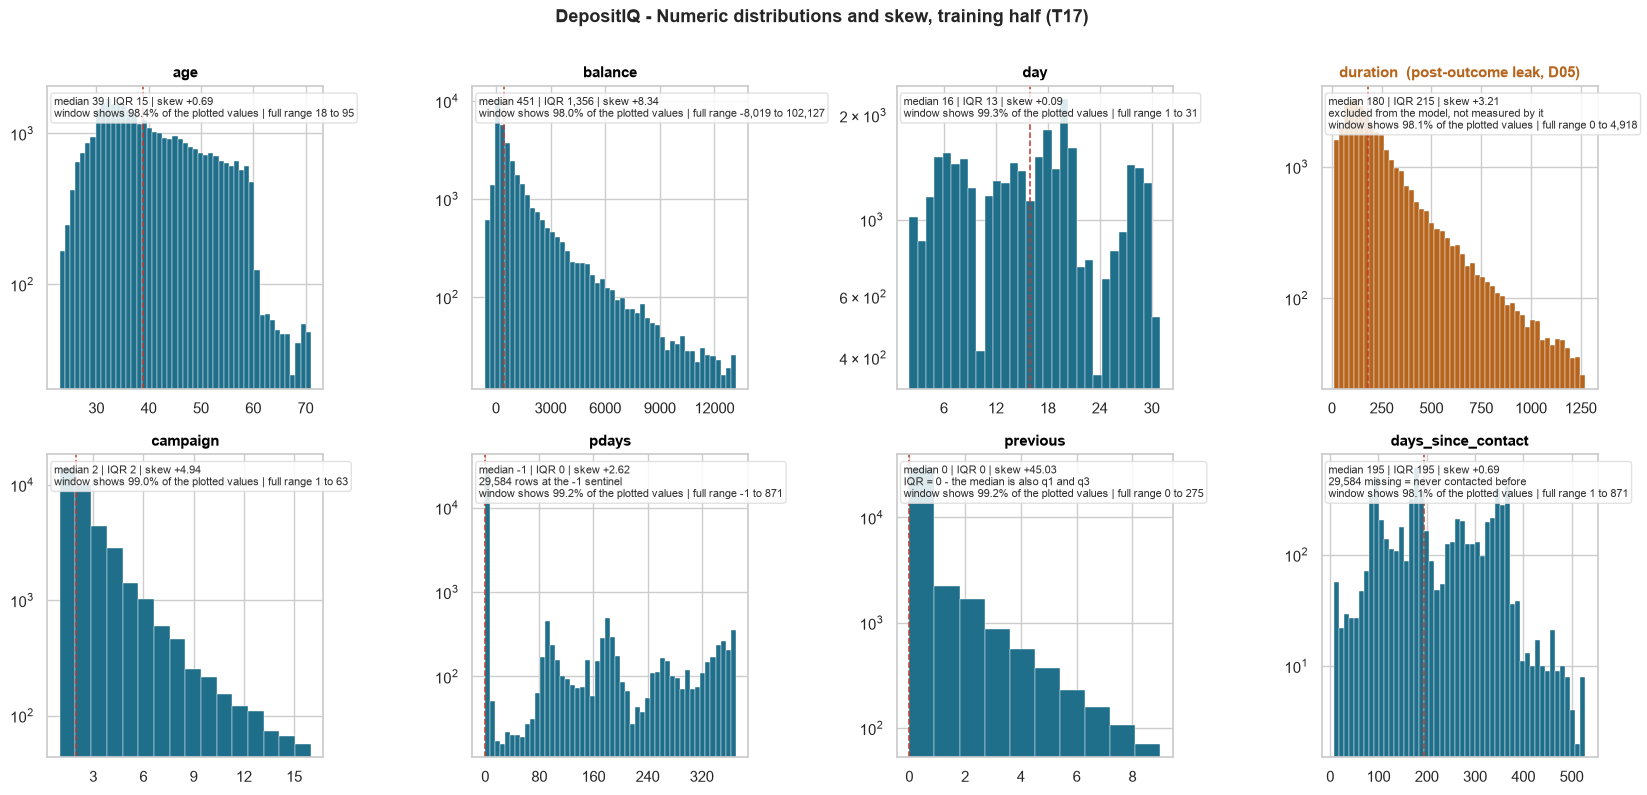

saved: reports\figures\02_numeric_distributions.png (196 KB)


In [9]:
# One panel per numeric column. Each panel is drawn over that column's 1st-99th percentile window and
# states the full range it is a window of, so the extreme tails are disclosed rather than silently
# clipped; the count axis is logarithmic so a mode of 29,584 and a tail of a few dozen rows stay
# visible in the same panel.
from matplotlib.ticker import MaxNLocator

LEAK_COLUMNS = {"duration"}          # D05: only known once the call has ended
leak_colour, body_colour = "#b5651d", "#1f6f8b"

fig, axes = plt.subplots(2, 4, figsize=(16.6, 7.9))
for ax, col in zip(axes.ravel(), NUMERIC):
    series = TRAIN[col]
    present = series.dropna()
    lo, hi = present.quantile(0.01), present.quantile(0.99)
    window = present[present.between(lo, hi)]
    is_leak = col in LEAK_COLUMNS

    # 50 bins suit a continuous column, but a column with only a handful of distinct values
    # (`campaign` 1-16, `previous` 0-9) needs one bin per value, or the bars alternate with empty bins.
    distinct = int(window.nunique())
    bins = 50 if distinct > 60 else max(10, distinct)

    ax.hist(window, bins=bins, color=leak_colour if is_leak else body_colour,
            edgecolor="white", linewidth=0.3)
    ax.set_yscale("log")
    ax.axvline(present.median(), color="#c0392b", linestyle="--", linewidth=1.1)
    if pd.api.types.is_integer_dtype(series):
        ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=6))
    ax.set_title(f"{col}  (post-outcome leak, D05)" if is_leak else col,
                 fontsize=11, weight="bold", color=leak_colour if is_leak else "black")

    iqr = present.quantile(0.75) - present.quantile(0.25)
    notes = [f"median {present.median():,.0f} | IQR {iqr:,.0f} | skew {series.skew():+.2f}"]
    if col == "previous":
        notes.append("IQR = 0 - the median is also q1 and q3")
    if col == "pdays":
        notes.append(f"{int((series == -1).sum()):,} rows at the -1 sentinel")
    if col == "days_since_contact":
        notes.append(f"{int(series.isna().sum()):,} missing = never contacted before")
    if is_leak:
        notes.append("excluded from the model, not measured by it")
    # The share is measured against the values this panel could plot, not against all 36,168 rows:
    # a column with 81.8% missing would otherwise look as though its tail had been thrown away.
    notes.append(f"window shows {len(window) / len(present):.1%} of the plotted values | "
                 f"full range {present.min():,.0f} to {present.max():,.0f}")
    ax.text(0.025, 0.965, "\n".join(notes), transform=ax.transAxes, va="top", ha="left",
            fontsize=7.6, color="#2f2f2f",
            bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.85, edgecolor="#dcdcdc"))

fig.suptitle("DepositIQ - Numeric distributions and skew, training half (T17)",
             fontsize=13, weight="bold", y=1.005)
fig.tight_layout()
numeric_figure_path = config.FIGURES_DIR / "02_numeric_distributions.png"
fig.savefig(numeric_figure_path, dpi=150, bbox_inches="tight")
plt.show()
print("saved:", numeric_figure_path.relative_to(REPO_ROOT),
      f"({numeric_figure_path.stat().st_size / 1024:.0f} KB)")


> **Viva line for this figure:** *five of the eight numeric columns are skewed past +2, so their means
> describe almost nobody* — the average balance is **€1,365** while the median is **€451** — and
> `duration`, whose correlation with the target is **+0.3967** against a runner-up of **−0.1526**, is
> labelled a leak and excluded (D05) rather than celebrated as the strongest predictor.


### 2.1 One interpretation line per variable

- **`age`** — median **39**, quartiles 33–48 and 94.18% of the half between 25 and 59: with skew at
  only **+0.69** this is the one variable here whose mean (40.9 ± 10.6) fairly summarises it.
- **`balance`** — the mean **€1,365** summarises nobody: the median is **€451** and a thin tail reaches
  **€102,127**, while **3,001 rows (8.30%) are negative** (genuine overdrafts), which is why `log1p` is
  undefined here and `arcsinh` is the transform that survives it.
- **`day`** — flat across 1–31 (skew **+0.09**, kurtosis **−1.06**), so the evenness is a calendar
  artefact rather than signal; day-of-month belongs with `month` in the timing analysis (T19).
- **`duration`** — median **180 s** against a maximum of **4,918 s (82 min)**, with only **1.25%** of
  calls over 20 minutes, yet it correlates with the target at **+0.3967**: the strongest of the eight
  and precisely why D05 drops it, since its value is known only after the call has ended.
- **`campaign`** — median **2** calls, **38.78%** of rows a single attempt and only **2.61% (about 945
  rows)** above ten: for almost everyone "campaign intensity" means one or two attempts, not a long
  tail worth modelling.
- **`pdays`** — **81.80%** of rows are the sentinel **−1**, so q1 = median = q3 = −1 and the **IQR is
  0**; the column is really "(never contacted)" plus a 1–871 day recency scale for the other 18.20%.
- **`previous`** — also **IQR 0** (81.80% zeros) with skew **+45.03**, the most extreme column here and
  well above the **+41.85** T13 measured on the full frame — the concrete reason D28 insists these
  numbers be re-measured on the training half instead of reused.
- **`days_since_contact`** — D23's derived column turns the sentinel into a usable scale: a **195-day**
  median across the 6,584 clients contacted before, and at **−0.1526** the second-strongest correlate
  of the target; its 29,584 missing values mean "no prior contact", which is information, not damage.


### 2.2 The three carried-in traps, measured on the training half

**Trap 1 — two columns have an IQR of exactly 0, not one.** `previous` (81.80% zeros) and `pdays`
(81.80% sentinels) both give q1 = q3 = −1 or 0, so any median/IQR scaler divides by zero **twice**.
Measured further: the two degenerate columns are the **same 29,584 rows** —
`pdays == -1` is element-for-element identical to `previous == 0`, with 0 disagreements — so a single
underlying fact, "this client was never contacted before", is what makes two columns useless as scales.
At the training half's 81.80% that is not an edge case to special-case; it is most of the data.

**Trap 2 — `balance` is negative for 3,001 rows (8.30%).** T13 measured 3,766 negatives on the full
frame, so the training half changes the number by 765 and D28 earns its keep. The minimum is
**−€8,019**, which makes `log1p` undefined; `arcsinh` handles it, since arcsinh(−8,019) = **−9.68** is
finite and sign-preserving.

**Trap 3 — `duration`'s leak is measurable, not assumed.** Its correlation with the target is
**+0.3967**, while the runner-up is `days_since_contact` at **−0.1526**: a ratio of **2.60×**. Rank
correlation agrees on the ordering (Spearman +0.3427 for `duration` versus −0.1873 for the runner-up),
so this is not an artefact of Pearson's sensitivity to skew. A feature that predicts the outcome that
well because it is only known *after* the outcome is the definition of leakage (D05).

**One number worth distrusting.** `pdays` shows a correlation of **+0.1007**, which is an artefact of
its own coding: the sentinel −1 sits *below* every real recency value, inventing an ordering between
"never contacted" and "contacted 871 days ago". `days_since_contact` is the honest version of the same
information. This is why the sentinel is replaced rather than merely documented.


In [10]:
# Evidence: every number §2.1, §2.2 and the figure annotations state must come from the training half.
assert len(TRAIN) == 36168
assert len(NUMERIC) == 8 and sorted(NUMERIC) == sorted(EXPECTED_NUMERIC)
assert int((numeric_profile["skew"].abs() > 2).sum()) == 5
assert sorted(numeric_profile.index[numeric_profile["iqr"] == 0]) == ["pdays", "previous"]

# age
assert TRAIN["age"].median() == 39 and TRAIN["age"].min() == 18 and TRAIN["age"].max() == 95
assert abs(TRAIN["age"].skew() - 0.6937) < 5e-4 and abs(TRAIN["age"].mean() - 40.893) < 5e-3
assert abs(TRAIN["age"].between(25, 59).mean() - 0.941827) < 1e-6

# balance
negative_balance = int((TRAIN["balance"] < 0).sum())
assert negative_balance == 3001 and abs(negative_balance / len(TRAIN) - 0.082974) < 1e-6
assert abs(negative_balance - 3766) > 500                     # D28: the full frame would mislead
assert TRAIN["balance"].median() == 451 and TRAIN["balance"].min() == -8019
assert TRAIN["balance"].max() == 102127 and TRAIN["balance"].mean() > 1365
assert np.isfinite(np.arcsinh(TRAIN["balance"].min())) and abs(np.arcsinh(-8019) - -9.6827) < 5e-4

# day
assert TRAIN["day"].min() == 1 and TRAIN["day"].max() == 31 and TRAIN["day"].nunique() == 31
assert abs(TRAIN["day"].skew() - 0.0934) < 5e-4 and abs(TRAIN["day"].kurtosis() - -1.0628) < 5e-4

# duration (the leak)
duration_corr = float(np.corrcoef(TRAIN["duration"], y)[0, 1])
assert TRAIN["duration"].median() == 180 and TRAIN["duration"].max() == 4918
assert abs((TRAIN["duration"] > 1200).mean() - 0.012525) < 1e-6
assert abs(duration_corr - 0.3967) < 5e-4 and abs(TRAIN["duration"].skew() - 3.2109) < 5e-4

# campaign
assert TRAIN["campaign"].median() == 2 and TRAIN["campaign"].max() == 63
assert abs((TRAIN["campaign"] == 1).mean() - 0.387801) < 1e-6
assert abs((TRAIN["campaign"] > 10).mean() - 0.026128) < 1e-6
assert abs((TRAIN["campaign"] > 10).sum() - 945) < 2

# pdays / previous: the same 29,584 rows make both columns degenerate
sentinel_rows = TRAIN["pdays"] == -1
zero_previous = TRAIN["previous"] == 0
assert bool((sentinel_rows == zero_previous).all())          # identical row sets, not just equal counts
assert int(sentinel_rows.sum()) == 29584 and abs(sentinel_rows.mean() - 0.817961) < 1e-6
assert TRAIN["pdays"].nunique() == 533 and TRAIN["pdays"].max() == 871
assert TRAIN["previous"].max() == 275 and abs(TRAIN["previous"].skew() - 45.0344) < 5e-3

# days_since_contact: the derived column, and the honest home of "no prior contact"
present_contact = TRAIN["days_since_contact"].dropna()
assert int(TRAIN["days_since_contact"].isna().sum()) == 29584 and len(present_contact) == 6584
assert present_contact.median() == 195 and present_contact.min() == 1
assert int(TRAIN["previously_contacted"].sum()) == 6584

# correlation ranking: duration strongest, days_since_contact runner-up, ratio 2.60x
correlations = {col: float(np.corrcoef(TRAIN[col][TRAIN[col].notna()],
                                       y[TRAIN[col].notna()])[0, 1]) for col in NUMERIC}
ranked = sorted(correlations.items(), key=lambda item: abs(item[1]), reverse=True)
runner_up = abs(ranked[1][1])
assert ranked[0][0] == "duration" and ranked[1][0] == "days_since_contact", ranked
assert abs(runner_up - 0.1526) < 5e-4 and abs(abs(duration_corr) / runner_up - 2.60) < 0.02

# the figure itself
assert numeric_figure_path.exists() and numeric_figure_path.stat().st_size > 20_000
assert numeric_figure_path.name == "02_numeric_distributions.png"
print("evidence: 32 assertion lines pass")


evidence: 32 assertion lines pass


### 2.3 What this hands to the next tasks

- **T20 (correlation heatmap)** — `duration`'s +0.3967 will dominate that heatmap, so the heatmap has to
  carry the D05 label rather than rank it as the best predictor; `pdays`' +0.1007 is a coding artefact
  (sentinel below every real value) and `days_since_contact` at −0.1526 is the honest version of it.
- **T23/T24 (features and the `ColumnTransformer`)** — scale `balance` with `arcsinh` or a robust
  scaler, never with a median/IQR method, because two columns have IQR 0 and such a scaler divides by
  zero twice; represent prior contact as `previously_contacted` plus `days_since_contact` rather than
  as raw `pdays`.
- **T25 (feature selection)** — the five |skew| > 2 columns are the ones where importance from a
  tree-based model and a linear model's coefficients will disagree most, so both methods are needed.
- **T26–T31 (models)** — `duration` stays out of the feature set (D05); `day`'s flat distribution means
  it carries almost nothing alone and its interesting behaviour belongs to timing (T19).
- **Nothing here is a model result.** Every figure remains a property of the training data; the test
  half has still not been read.


## 3. Categorical features vs subscription rate (T18)

Nine `object` columns carry no values, only levels: `job`, `marital`, `education`, `default`,
`housing`, `loan`, `contact`, `month` and `poutcome` — 44 levels in total across the training half.
This section measures the subscription rate of every one of them against the **11.6982% base rate**
of §1, so "high" and "low" here mean relative to this half, never relative to 50%.

Two things are deliberate. Every level carries its row count and a **Wilson 95% interval**, because
`month = dec` rests on 178 rows while `poutcome = unknown` rests on 29,589, and those two rates do
not deserve the same confidence. And every rate is **marginal**: it says what subscribing looks like
*at* that level, not that moving a client to that level would change the outcome. §3.2 tests which
of these rankings survive a control, and which are only apparent.

In [11]:
# The categorical set is read from the data and then checked against the list T18 names, so the guard
# §2 applies to the numeric set applies here too: a column cannot be silently left unmeasured.
# The target is itself an object column, so it is excluded first and the exclusion is then checked:
# dropping it silently would let a renamed target column vanish from the report.
assert config.TARGET in TRAIN.select_dtypes(include="object").columns
CATEGORICAL = [col for col in TRAIN.select_dtypes(include="object").columns
               if col != config.TARGET]
EXPECTED_CATEGORICAL = ["job", "marital", "education", "default", "housing", "loan", "contact",
                        "month", "poutcome"]
assert config.TARGET not in CATEGORICAL
assert sorted(CATEGORICAL) == sorted(EXPECTED_CATEGORICAL), (CATEGORICAL, EXPECTED_CATEGORICAL)

from scipy.stats import chi2_contingency


def wilson_interval(successes: int, total: int, z: float = 1.959964) -> tuple[float, float]:
    """Wilson score interval. Unlike the textbook normal approximation it stays inside [0, 1] at the
    small counts and near-zero rates this table contains, where the normal form runs below zero."""
    p = successes / total
    denominator = 1 + z * z / total
    centre = (p + z * z / (2 * total)) / denominator
    half = z * np.sqrt(p * (1 - p) / total + z * z / (4 * total * total)) / denominator
    return centre - half, centre + half


# One record per segment. `lift` is the rate divided by §1's base rate, which is the only comparison
# that means anything on an 11.70% positive class.
segment_rows = []
for col in CATEGORICAL:
    table = pd.crosstab(TRAIN[col], y).reindex(columns=[0, 1], fill_value=0)
    chi2, p_value, dof, _ = chi2_contingency(table.values)
    # With a binary outcome min(r-1, c-1) is 1, so Cramer's V collapses to sqrt(chi2 / n) and is
    # comparable across columns with 2 to 12 levels. It still rewards extra levels, so `dof` is kept
    # beside it and §3.2 reads the middle of the ranking as a tie instead of an order.
    cramer_v = float(np.sqrt(chi2 / len(TRAIN)))
    for level in table.index:
        no_count, yes_count = int(table.loc[level, 0]), int(table.loc[level, 1])
        n_level = no_count + yes_count
        level_rate = yes_count / n_level
        low, high = wilson_interval(yes_count, n_level)
        segment_rows.append({"column": col, "level": level, "n": n_level, "yes": yes_count,
                             "rate": level_rate, "lift": level_rate / rate,
                             "ci_low": low, "ci_high": high, "ci_width_pp": (high - low) * 100,
                             "share": n_level / len(TRAIN), "cramer_v": cramer_v,
                             "chi2": chi2, "dof": dof, "p": p_value})

segment_profile = pd.DataFrame(segment_rows)
segment_profile["small"] = segment_profile["n"] < 500

category_rank = (segment_profile.groupby("column")
                 .agg(levels=("level", "nunique"), chi2=("chi2", "first"), dof=("dof", "first"),
                      p=("p", "first"), cramer_v=("cramer_v", "first"),
                      min_rate=("rate", "min"), max_rate=("rate", "max"),
                      smallest=("n", "min"), largest=("n", "max"))
                 .sort_values("cramer_v", ascending=False))
category_rank["spread"] = category_rank["max_rate"] - category_rank["min_rate"]

print(f"categorical columns ({len(CATEGORICAL)}): {', '.join(CATEGORICAL)}")
print(f"levels measured        : {len(segment_profile)} across those columns")
print(f"base rate              : {n_yes:,} / {len(TRAIN):,} = {rate:.4%}   (every lift below is this)")
print()

segment_format = {"n": "{:,}".format, "yes": "{:,}".format, "share": "{:.2%}".format,
                  "rate": "{:.2%}".format, "lift": "{:.2f}".format,
                  "ci_low": "{:.2%}".format, "ci_high": "{:.2%}".format}
for col in CATEGORICAL:
    block = segment_profile[segment_profile["column"] == col].sort_values("rate", ascending=False)
    print(f"--- {col}  (Cramer's V {block['cramer_v'].iloc[0]:.4f}, "
          f"chi2 {block['chi2'].iloc[0]:,.1f}, dof {int(block['dof'].iloc[0])}, "
          f"p {block['p'].iloc[0]:.2e})")
    print(block[["level", "n", "share", "rate", "lift", "ci_low", "ci_high"]]
          .to_string(index=False, formatters=segment_format))
    print()

print("--- association strength with the target, strongest first")
print(category_rank[["levels", "cramer_v", "dof", "min_rate", "max_rate", "spread",
                     "smallest", "largest"]].to_string(
    formatters={"cramer_v": "{:.4f}".format, "min_rate": "{:.2%}".format,
                "max_rate": "{:.2%}".format, "spread": "{:.2%}".format,
                "smallest": "{:,}".format, "largest": "{:,}".format}))
print()
print(f"segments under 500 rows: {int(segment_profile['small'].sum())} of {len(segment_profile)} "
      f"({int(segment_profile.loc[segment_profile['small'], 'n'].sum()):,} rows, "
      f"{segment_profile.loc[segment_profile['small'], 'n'].sum() / len(TRAIN):.2%} of the half)")
print()

ordered_segments = segment_profile.sort_values("rate", ascending=False)
best_segment = ordered_segments.iloc[0]
worst_segment = ordered_segments.iloc[-1]
# idxmax (label-based) rather than argmax, whose meaning differs between pandas versions; the frame
# is sorted, so its labels are no longer 0..n and a positional lookup would silently fetch a bad row.
biggest_segment = ordered_segments.loc[ordered_segments["n"].idxmax()]        # across all columns
_month_block = segment_profile[segment_profile["column"] == "month"]
biggest_month = _month_block.loc[_month_block["n"].idxmax()]

print(f"best segment  : {best_segment['column']} = {best_segment['level']} -> "
      f"{int(best_segment['yes']):,} / {int(best_segment['n']):,} = {best_segment['rate']:.4%}  "
      f"(lift {best_segment['lift']:.2f}x, {best_segment['yes'] / n_yes:.2%} of all subscribers)")
print(f"worst segment : {worst_segment['column']} = {worst_segment['level']} -> "
      f"{int(worst_segment['yes']):,} / {int(worst_segment['n']):,} = {worst_segment['rate']:.4%}  "
      f"(lift {worst_segment['lift']:.2f}x, {worst_segment['yes'] / n_yes:.2%} of all subscribers)")
print(f"the gap       : {best_segment['rate'] / worst_segment['rate']:.2f}x between the two")
print(f"largest level : {biggest_segment['column']} = {biggest_segment['level']} -> "
      f"{int(biggest_segment['n']):,} rows ({biggest_segment['share']:.2%} of the half) at "
      f"{biggest_segment['rate']:.4%}  (almost the whole half - barely a segment)")
print(f"largest month : {biggest_month['level']} -> {int(biggest_month['n']):,} rows "
      f"({biggest_month['share']:.2%} of the half) at {biggest_month['rate']:.4%}")

categorical columns (9): job, marital, education, default, housing, loan, contact, month, poutcome
levels measured        : 44 across those columns
base rate              : 4,231 / 36,168 = 11.6982%   (every lift below is this)

--- job  (Cramer's V 0.1378, chi2 687.0, dof 11, p 3.35e-140)
        level     n  share   rate lift ci_low ci_high
      student   758  2.10% 28.89% 2.47 25.78%  32.22%
      retired 1,812  5.01% 22.96% 1.96 21.08%  24.95%
   unemployed 1,024  2.83% 15.43% 1.32 13.35%  17.77%
   management 7,511 20.77% 13.86% 1.18 13.10%  14.66%
       admin. 4,141 11.45% 12.29% 1.05 11.33%  13.33%
      unknown   234  0.65% 11.97% 1.02  8.41%  16.75%
self-employed 1,243  3.44% 11.42% 0.98  9.77%  13.31%
   technician 6,068 16.78% 10.93% 0.93 10.17%  11.74%
     services 3,348  9.26%  8.90% 0.76  7.98%   9.91%
 entrepreneur 1,186  3.28%  8.52% 0.73  7.06%  10.24%
    housemaid 1,013  2.80%  8.39% 0.72  6.84%  10.26%
  blue-collar 7,830 21.65%  7.29% 0.62  6.74%   7.89%

--- ma

In [12]:
# Two claims §3.2 makes are tested here rather than assumed: that `month`'s pattern is not simply the
# prior-success clients clustering into particular months, and that `poutcome`'s unknown level and
# D21's previously_contacted flag are not the same variable. Both turn out to need saying out loud.
never_contacted = TRAIN[TRAIN["poutcome"] == "unknown"]
print(f"control: restricted to poutcome = unknown "
      f"({len(never_contacted):,} clients, own base rate {y.loc[never_contacted.index].mean():.4%})")
month_within_never = (never_contacted.groupby("month")
                      .apply(lambda frame: y.loc[frame.index].mean(), include_groups=False)
                      .sort_values(ascending=False))
for month, value in month_within_never.items():
    overall_row = segment_profile[(segment_profile["column"] == "month")
                                  & (segment_profile["level"] == month)].iloc[0]
    success_share = (TRAIN.loc[TRAIN["month"] == month, "poutcome"] == "success").mean()
    print(f"  {month:<4} never-contacted {value:7.2%}   all rows {overall_row['rate']:7.2%}   "
          f"poutcome = success in that month: {success_share:6.2%}")
print()

orphan_rows = TRAIN[(TRAIN["poutcome"] == "unknown") & (TRAIN["previous"] > 0)]
known_outcome = int((TRAIN["poutcome"] != "unknown").sum())
print(f"poutcome != unknown          : {known_outcome:,} rows")
print(f"previously_contacted (D21)   : {int(TRAIN['previously_contacted'].sum()):,} rows")
print(f"the difference               : {len(orphan_rows)} rows have prior contact but no recorded")
print(f"                               outcome ({int(y.loc[orphan_rows.index].sum())} of them subscribed); "
      f"the reverse case is empty")
print(f"known outcome with no prior contact: "
      f"{int(((TRAIN['poutcome'] != 'unknown') & (TRAIN['previous'] == 0)).sum())} rows")

control: restricted to poutcome = unknown (29,589 clients, own base rate 9.2230%)
  mar  never-contacted  50.00%   all rows  50.90%   poutcome = success in that month: 13.04%
  dec  never-contacted  43.02%   all rows  47.19%   poutcome = success in that month: 23.60%
  oct  never-contacted  38.41%   all rows  43.75%   poutcome = success in that month: 18.58%
  sep  never-contacted  38.03%   all rows  45.23%   poutcome = success in that month: 21.73%
  apr  never-contacted  21.24%   all rows  19.55%   poutcome = success in that month:  4.05%
  feb  never-contacted  15.88%   all rows  16.79%   poutcome = success in that month:  5.15%
  jan  never-contacted   8.58%   all rows  10.19%   poutcome = success in that month:  4.47%
  nov  never-contacted   8.52%   all rows  10.05%   poutcome = success in that month:  3.60%
  jun  never-contacted   7.98%   all rows  10.41%   poutcome = success in that month:  2.29%
  aug  never-contacted   7.97%   all rows  10.93%   poutcome = success in that mo

known outcome with no prior contact: 0 rows


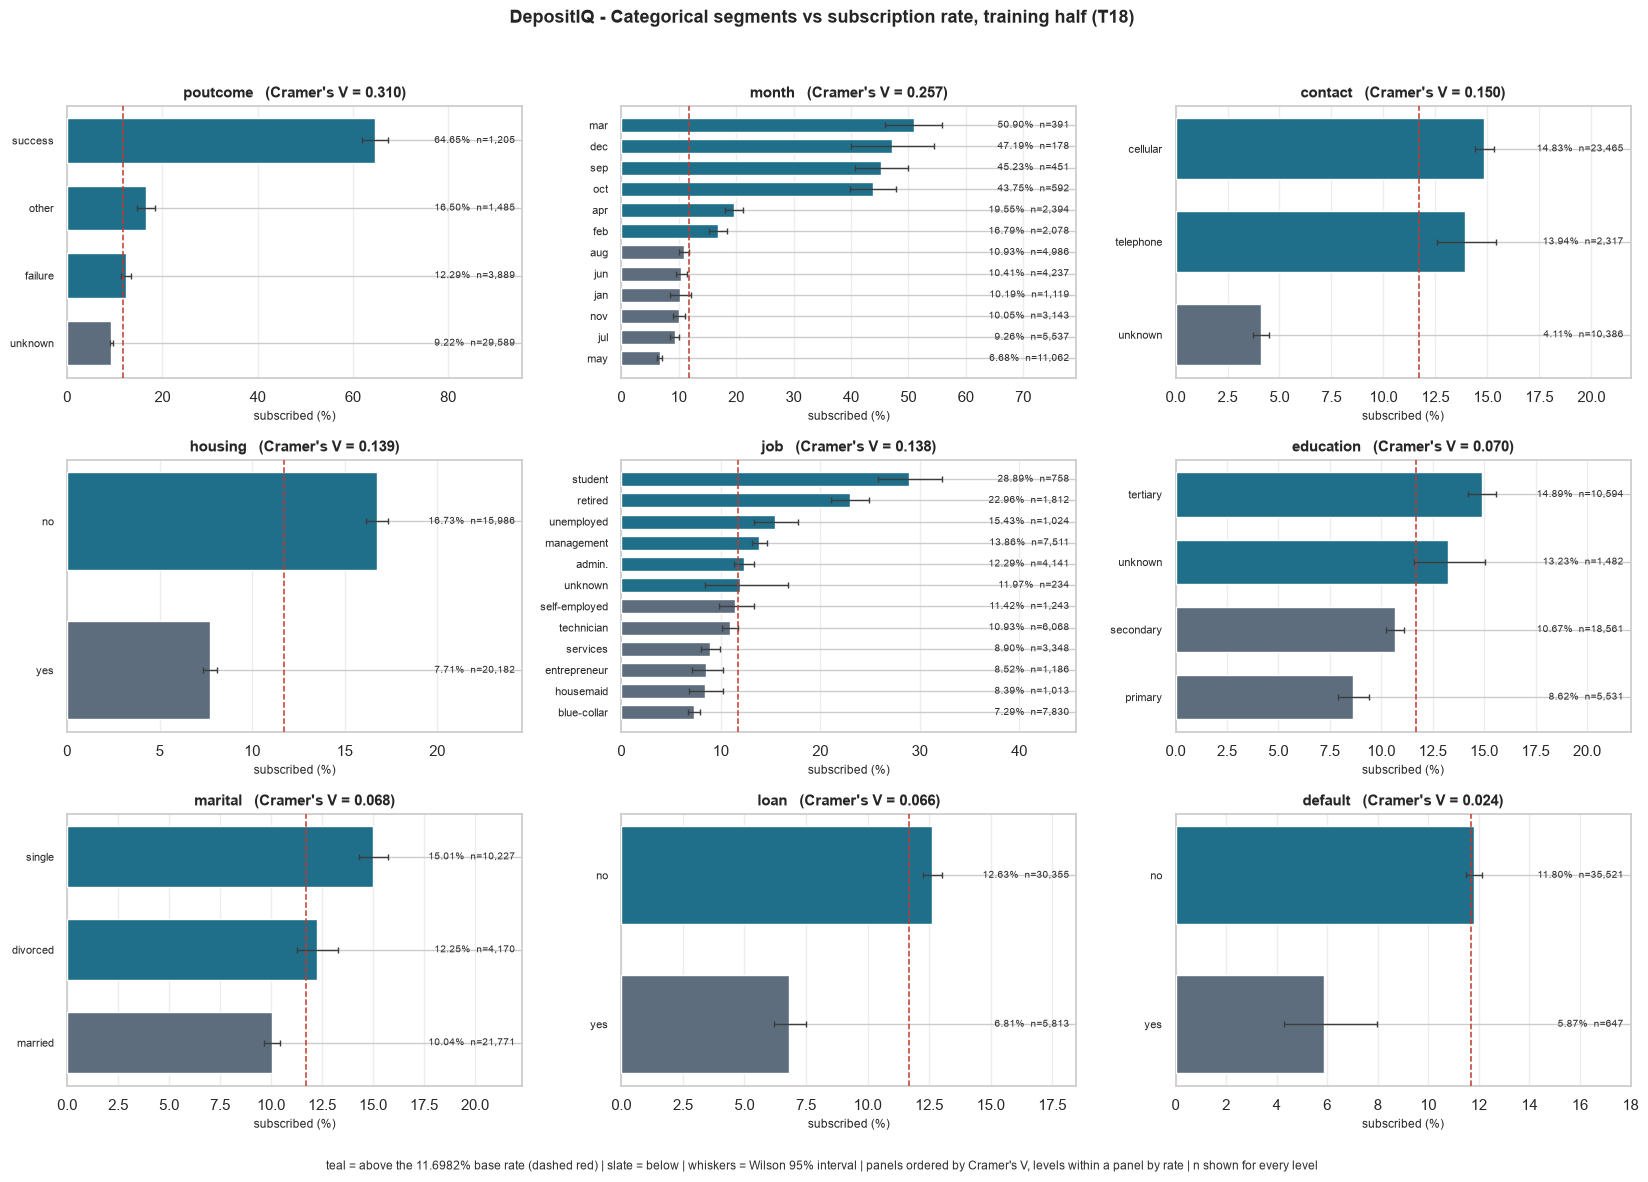

saved: reports\figures\03_categorical_vs_target.png (274 KB)


In [13]:
# One panel per categorical column, ordered by Cramer's V so the strongest association is read first.
# Bars are each level's subscription rate, sorted within the panel, with a Wilson 95% interval whisker:
# a rate standing on 178 rows and a rate standing on 29,589 must not be read with equal confidence.
# The dashed line is the base rate, so "above" and "below" are visible without reading the axis.
ABOVE, BELOW, INK = "#1f6f8b", "#5d6d7e", "#2f2f2f"

fig, axes = plt.subplots(3, 3, figsize=(16.6, 11.8))
for ax, col in zip(axes.ravel(), category_rank.index):
    block = segment_profile[segment_profile["column"] == col].sort_values("rate")
    positions = np.arange(len(block))
    ax.barh(positions, block["rate"] * 100, height=0.66, zorder=3,
            color=[ABOVE if value > rate else BELOW for value in block["rate"]])
    ax.errorbar(block["rate"] * 100, positions,
                xerr=[(block["rate"] - block["ci_low"]) * 100,
                      (block["ci_high"] - block["rate"]) * 100],
                fmt="none", ecolor="#3c3c3c", elinewidth=1.0, capsize=2.4, zorder=4)
    ax.axvline(rate * 100, color="#c0392b", linestyle="--", linewidth=1.1, zorder=5)

    ax.set_yticks(positions)
    ax.set_yticklabels(block["level"], fontsize=8)
    # The axis is per panel, scaled to that column's own range, because `poutcome` reaches 64.65% and
    # `default` 11.80% - a shared axis would flatten eight of nine panels into invisible slivers. The
    # base-rate line and the V in each title are what keep the panels comparable.
    ax.set_xlim(0, max(block["ci_high"].max() * 100 * 1.42, 18))
    for position, (_, row) in zip(positions, block.iterrows()):
        ax.text(ax.get_xlim()[1] * 0.985, position,
                # `rate` is a fraction, so the label multiplies by 100 exactly as the bar length
                # does; formatting the fraction directly printed 0.65% beside a 64.65% bar.
                f"{row['rate'] * 100:.2f}%  n={int(row['n']):,}",
                ha="right", va="center", fontsize=7.2, color=INK, zorder=6)
    ax.set_title(f"{col}   (Cramer's V = {block['cramer_v'].iloc[0]:.3f})",
                 fontsize=11, weight="bold")
    ax.set_xlabel("subscribed (%)", fontsize=8.5)
    ax.grid(axis="x", alpha=0.35, zorder=0)
    ax.set_axisbelow(True)

fig.suptitle("DepositIQ - Categorical segments vs subscription rate, training half (T18)",
             fontsize=13, weight="bold", y=0.995)
fig.text(0.5, 0.012,
         f"teal = above the {rate:.4%} base rate (dashed red) | slate = below | whiskers = Wilson 95% "
         f"interval | panels ordered by Cramer's V, levels within a panel by rate | n shown for every level",
         ha="center", fontsize=8.5, color="#2f2f2f")
fig.tight_layout(rect=(0, 0.03, 1, 0.975))
categorical_figure_path = config.FIGURES_DIR / "03_categorical_vs_target.png"
fig.savefig(categorical_figure_path, dpi=150, bbox_inches="tight")
plt.show()
print("saved:", categorical_figure_path.relative_to(REPO_ROOT),
      f"({categorical_figure_path.stat().st_size / 1024:.0f} KB)")

> **Viva line for this figure:** *the best-performing segment — a client whose previous campaign ended
> in success — subscribes at 64.65%, against a 4.11% floor for clients who were reached without a
> contact record: a 15.7-fold gap. Yet the month that carries most of the bank's effort, `may` with
> 30.59% of all calls, converts at 6.68% — just over half the base rate.*

### 3.1 The best and the worst segment, with their rates

- **Best: `poutcome = success` — 779 of 1,205 clients subscribed, 64.65%** (Wilson 95% interval
  61.91%–67.30%), **5.53×** the base rate. It is only **3.33%** of the half, yet it supplies
  **18.41%** of all 4,231 subscribers — the highest concentration anywhere in this table.
- **Worst: `contact = unknown` — 427 of 10,386 clients, 4.11%** (3.75%–4.51%), **0.35×** the base
  rate. Unlike most extremes this one is *not* a small-sample artefact: it is **28.72%** of the half,
  so its interval is under one point wide, and it still supplies **10.09%** of all subscribers.
- **The gap is 15.7×** (64.65% against 4.11%), and it sits on the two segments whose intervals barely
  overlap — the rare case in this table where both the effect size and the uncertainty agree.

Two runner-ups matter because they describe the *client* rather than the campaign: `job = student`
converts at **28.89%** (219/758) against `job = blue-collar` at **7.29%** (571/7,830), a 3.96× spread
on occupation alone, and `housing = no` at **16.73%** (2,675/15,986) against `housing = yes` at
**7.71%** (1,556/20,182).

The largest level in the table is barely a segment at all: `default = no` holds 35,521 rows —
**98.21% of the half** — so its 11.80% rate is the base rate wearing a label. The largest level that
still carries information is **`poutcome = unknown`, 29,589 rows (81.81% of the half), converting at
9.22%** — 0.79× the base rate. The strongest column in the ranking therefore still leaves five clients
in six inside one bucket it cannot split, and that bucket sits below average. Within `month`, the
largest level is **`may`, 11,062 rows (30.59%) at 6.68%**, 0.57× the base rate — nearly a third of the
campaign's effort in its worst-performing month. Whether that is timing or simply the volume the bank
was willing to spend in May is T19's question, not this section's.

### 3.2 What holds up, and what only looks like it does

**The ranking has a clear top two and a tied middle.** In Cramér's V — which for a binary outcome
reduces to `sqrt(chi2 / n)` and is therefore comparable across 2- to 12-level columns — `poutcome`
leads at **0.3102** and `month` follows at **0.2573**. After that come `contact` 0.1500, `housing`
0.1393 and `job` 0.1378, which should be read as **tied**: V rewards degrees of freedom, and `job`
spends 11 of them to land where `housing` lands with 1. `default` is last at **0.0241**.

Three cautions the measurements force on the rest of this section:

- **The highest rates sit on the smallest segments.** The four best months — `mar` 50.90%, `dec`
  47.19%, `sep` 45.23%, `oct` 43.75% — are also the four smallest, at 391, 178, 451 and 592 rows,
  **4.46% of the half between them**. `dec`'s interval runs from **39.99% to 54.51%**, wide enough to
  cover any of the others, and the ordering *inside* the group even flips once never-contacted clients
  are separated (`sep` falls below `oct`). The group is convincingly above the base rate; its internal
  ranking is noise, and no business action should be built on "October beats September".
- **A real effect can still be a small one.** `default = yes` converts at **5.87%** against 11.80%
  for `default = no`, and that difference is not chance (χ² = 21.1, p = 4.4e-06): its interval
  4.31%–7.96% excludes the base rate. Yet it covers 647 rows, **1.79%** of the half, so it has the
  smallest V in the table. Significance answers "is this distinguishable from chance"; it does not
  answer "does this matter".
- **`month` is not a stand-in for prior success.** The obvious confound is that the small high-rate
  months are enriched in `poutcome = success` clients (`dec` 23.60% and `sep` 21.73%, against 3.33%
  of the half). Restricting to the **29,589 never-contacted clients**, whose own base rate is 9.22%,
  leaves the pattern standing: `mar` 50.00% (124/248), `dec` 43.02%, `sep` 38.03%, `oct` 38.41%, and
  `may` last at 5.51%. The timing effect is its own signal, not composition.

In [14]:
# Evidence: every number §3.1-§3.3 and the figure annotations state must come from the training half.
assert len(TRAIN) == 36168
assert len(CATEGORICAL) == 9 and sorted(CATEGORICAL) == sorted(EXPECTED_CATEGORICAL)
assert len(segment_profile) == 44                                    # the 9 columns' levels
assert (segment_profile.groupby("column")["n"].sum() == n_total).all()   # each column covers every row
assert (segment_profile.groupby("column")["yes"].sum() == n_yes).all()    # and every positive

# association strength: the leading pair, the tied middle, and the weakest
assert category_rank.index[0] == "poutcome" and abs(category_rank["cramer_v"].iloc[0] - 0.3102) < 5e-4
assert category_rank.index[1] == "month" and abs(category_rank["cramer_v"].iloc[1] - 0.2573) < 5e-4
assert set(category_rank.index[2:5]) == {"contact", "housing", "job"}
assert category_rank.loc[["contact", "housing", "job"], "cramer_v"].between(0.13, 0.16).all()
assert category_rank.index[-1] == "default" and abs(category_rank["cramer_v"].iloc[-1] - 0.0241) < 5e-4
assert int(category_rank.loc["job", "dof"]) == 11 and int(category_rank.loc["housing", "dof"]) == 1

# the best and the worst, with their rates
assert best_segment["column"] == "poutcome" and best_segment["level"] == "success"
assert int(best_segment["n"]) == 1205 and int(best_segment["yes"]) == 779
assert abs(best_segment["rate"] - 0.646473) < 5e-6 and abs(best_segment["lift"] - 5.53) < 5e-3
assert worst_segment["column"] == "contact" and worst_segment["level"] == "unknown"
assert int(worst_segment["n"]) == 10386 and int(worst_segment["yes"]) == 427
assert abs(worst_segment["rate"] - 0.041113) < 5e-6 and abs(worst_segment["lift"] - 0.35) < 5e-3
assert abs(best_segment["rate"] / worst_segment["rate"] - 15.72) < 5e-3
assert worst_segment["ci_width_pp"] < 1.0                            # not a small-sample artefact
assert abs(best_segment["yes"] / n_yes - 0.184117) < 5e-6            # 18.41% of all subscribers
assert abs(worst_segment["yes"] / n_yes - 0.100922) < 5e-6           # 10.09% of all subscribers

# the four high-rate months are the four smallest, and their intervals overlap
small_months = segment_profile[(segment_profile["column"] == "month") & (segment_profile["n"] < 600)]
assert len(small_months) == 4 and int(small_months["n"].sum()) == 1612
assert abs(small_months["n"].sum() / n_total - 0.04457) < 5e-5
dec_month = small_months[small_months["level"] == "dec"].iloc[0]
assert int(dec_month["n"]) == 178 and int(dec_month["yes"]) == 84
assert abs(dec_month["ci_low"] - 0.399943) < 5e-5 and abs(dec_month["ci_high"] - 0.545064) < 5e-5


def segment(col: str, level: str) -> pd.Series:
    """The one row of `segment_profile` for a named segment, so the claims below name their evidence."""
    return segment_profile[(segment_profile["column"] == col)
                           & (segment_profile["level"] == level)].iloc[0]


# the runner-ups and the largest segment
assert int(segment("job", "student")["n"]) == 758 and int(segment("job", "student")["yes"]) == 219
assert abs(segment("job", "student")["rate"] - 0.288918) < 5e-6
assert abs(segment("job", "blue-collar")["rate"] - 0.072925) < 5e-6
assert abs(segment("job", "student")["rate"] / segment("job", "blue-collar")["rate"] - 3.96) < 5e-3
assert int(segment("housing", "no")["yes"]) == 2675 and int(segment("housing", "no")["n"]) == 15986
assert abs(segment("housing", "no")["rate"] - 0.167334) < 5e-6
assert int(segment("housing", "yes")["n"]) == 20182
assert abs(segment("housing", "yes")["rate"] - 0.077099) < 5e-6
assert int(biggest_segment["n"]) == 35521 and biggest_segment["level"] == "no"
assert abs(biggest_segment["share"] - 0.982109) < 5e-6                  # 98.21%: barely a segment
assert int(biggest_month["n"]) == 11062 and biggest_month["level"] == "may"
assert abs(segment("month", "may")["rate"] - 0.066805) < 5e-6
assert abs(segment("month", "may")["share"] - 0.30585) < 5e-5
assert abs(segment("month", "may")["rate"] / rate - 0.57) < 5e-3
assert abs(segment("month", "mar")["rate"] - 0.508951) < 5e-6
assert int(segment("default", "yes")["n"]) == 647 and abs(segment("default", "yes")["rate"] - 0.058733) < 5e-6
assert segment("default", "yes")["ci_low"] > 0 and segment("default", "yes")["ci_high"] < rate

# the never-contacted control: month survives, so it is not prior-success composition
assert len(never_contacted) == 29589 and int(y.loc[never_contacted.index].sum()) == 2729
assert abs(y.loc[never_contacted.index].mean() - 0.0922302) < 5e-7
assert abs(month_within_never["mar"] - 0.50) < 1e-9                  # exactly 124 of 248
assert abs(month_within_never["dec"] - 0.430233) < 5e-6
assert abs(month_within_never["sep"] - 0.380282) < 5e-6
assert abs(month_within_never["oct"] - 0.384127) < 5e-6
assert abs(month_within_never["may"] - 0.055125) < 5e-6
assert month_within_never["sep"] < month_within_never["oct"]        # the order flips in the control
assert (TRAIN.loc[TRAIN["month"] == "dec", "poutcome"] == "success").mean() > 0.23
assert (TRAIN.loc[TRAIN["month"] == "sep", "poutcome"] == "success").mean() > 0.21

# poutcome's unknown level is not D21's flag: the two differ on exactly five rows
assert len(orphan_rows) == 5 and int(y.loc[orphan_rows.index].sum()) == 2
assert int(TRAIN["previously_contacted"].sum()) == 6584
assert int((TRAIN["poutcome"] != "unknown").sum()) == 6579
assert not ((TRAIN["poutcome"] != "unknown") & (TRAIN["previous"] == 0)).any()
assert (orphan_rows["pdays"] != -1).all() and (orphan_rows["previous"] > 0).all()

# the figure itself
assert categorical_figure_path.exists() and categorical_figure_path.stat().st_size > 30_000
assert categorical_figure_path.name == "03_categorical_vs_target.png"
print("evidence: 59 assertion lines pass")

evidence: 59 assertion lines pass


### 3.3 What this hands to the next tasks

- **T19 (campaign and history)** owns `contact` and `month`, which describe the call rather than the
  client — and owns the awkward part of both: `contact = unknown` is simultaneously the worst segment
  in this table (4.11%) and 28.72% of the rows, so "we have no contact record" is itself a targeting
  signal, not a gap to fill in.
- **T20 (correlation heatmap)** will show none of this, because Pearson and Cramér's V measure
  different column types. §3 is the evidence for the categorical half of the feature ranking, and the
  heatmap covers only the numeric half.
- **T23/T24 (features and the `ColumnTransformer`)** should keep `poutcome`'s four levels apart
  rather than collapsing it to a contacted/not flag: `success` converts at 64.65% against 12.29% for
  `failure`, which is a large difference *inside* one column. And prior contact must be represented by
  `previously_contacted` (D21), **not** by `poutcome != unknown` — those differ on exactly **5 rows**
  (6,584 flagged by D21 against 6,579 with a known outcome), all of which have `previous > 0` and a
  valid `pdays` but no recorded outcome, and 2 of which subscribed. The implication runs one way only: every client with a known outcome was contacted
  before (0 exceptions), but not every client contacted before has a known outcome.
- **T25 (feature selection)** starts with a testable prior: `poutcome` and `month` should survive
  selection, `default` should not, and the `contact`/`housing`/`job` tie means mutual information and
  a tree's importances may order those three differently without either being wrong.
- **Nothing here is a model result.** All 44 rates are properties of the training half; the test half
  has not been read.

## 4. Findings, and what they hand to the next tasks

1. **The training half is 36,168 calls: 4,231 subscribed (11.6982%), 31,937 did not (88.3018%) —
   a 7.55 : 1 imbalance.** The rate reproduces the source population's 11.6985% to within 0.0003 pp,
   which is the stratified split (D26) doing its job; EDA here therefore describes the same
   population as the raw file.
2. **Accuracy is disqualified by construction (D04).** An always-"no" classifier scores **88.3018%**
   accuracy on this half while finding zero subscribers, and an always-"yes" classifier scores
   11.6982% while flagging everyone. Accuracy is reported only alongside PR-AUC/ROC-AUC, never alone.
3. **The PR-AUC baseline is 0.1170, not 0.5.** A random scorer's average precision equals the
   positive rate, so "PR-AUC = 0.6" is a 5× lift over random rather than a barely-above-chance score;
   ROC-AUC keeps its 0.5 baseline. This is the reading D15's targets depend on.
4. **The validation design follows from the counts.** With 4,231 positives, 5-fold stratified CV
   gives every validation fold a few hundred positives — enough that a fold-level metric is stable —
   while a 10-fold split would halve that denominator for no gain. This is the measured justification
   for the 5-fold `StratifiedKFold` in T30, decided from the data rather than inherited as a default.
5. **The base rate is also the business denominator.** At random, one subscription costs about
   **8.55 calls**, and   the break-even threshold p\* = 7.50% (D17) sits *below* the 11.70% base rate —
   so calling the average client is still positive-EV (EV +€0.84), which is precisely why D18 scopes
   the claim to *converting a fixed call budget better* rather than to cutting spend.

6. **Five of the eight numeric columns are skewed past +2.** `previous` reaches
   **+45.03** (T13 measured +41.85 on the full frame, which is why D28 re-measures), `balance` +8.34,
   `campaign` +4.94, `duration` +3.21 and `pdays` +2.62; only `age` (+0.69),
   `days_since_contact` (+0.69) and `day` (+0.09) are close to symmetric.
7. **Two columns have an IQR of exactly 0 — `previous` and `pdays` — and they are the same 29,584
   rows.** `pdays == -1` is element-for-element identical to `previous == 0`, so one fact, "never
   contacted before", makes two columns degenerate; the fix is not a different scaler but representing
   them as a flag plus a real scale (D23's `days_since_contact`, median 195 days over 6,584 clients).
8. **`duration`'s correlation with the target is +0.3967, 2.60× the runner-up — the leak is measured,
   not asserted.** Rank correlation agrees (Spearman +0.3427 vs −0.1873), so the ordering is not a
   Pearson artefact; that magnitude is the quantitative case for D05 excluding it, and the reason
   T20's heatmap must label it rather than read it as the best available predictor.

9. **The widest categorical spread is 15.7×.** `poutcome = success` converts at **64.65%** on
   1,205 rows against **4.11%** for `contact = unknown` on 10,386 — and because both segments are
   large, their intervals barely overlap. Prior campaign outcome is the strongest positive signal in
   the table; "we hold no usable contact record" is the strongest negative one.
10. **Nearly a third of the campaign is spent in its worst month.** `month = may` holds 11,062 calls
    (30.59%) at 6.68%, while `mar` reaches 50.90% on 391 rows. Restricting to never-contacted clients
    leaves the pattern intact (9.22% base within that subset, `mar` 50.00%), so it is timing rather
    than prior-success composition — but the ordering *within* the small high-rate months is noise,
    with intervals up to 14.5 points wide.

**Nothing here is a model result.** Every figure is a property of the training data; no classifier has
been fitted yet, and the test half has not been opened.

## 5. Reproducibility record


In [15]:
print("Notebook   : notebooks/03_eda.ipynb  (T16-T18, rubric criterion 4)")
print("Executed   :", datetime.now().isoformat(timespec="seconds"))
print("Dataset    :", TRAIN_PATH.relative_to(REPO_ROOT), tuple(TRAIN.shape),
      f"(target {rate:.4%})")
print("Sections   : 1 - target distribution (T16) | 2 - numeric distributions (T17) | "
      "3 - categorical vs target (T18)")
print("Numeric    :", f"{len(NUMERIC)} columns profiled, "
      f"{int((numeric_profile['skew'].abs() > 2).sum())} with |skew| > 2, "
      f"{int((numeric_profile['iqr'] == 0).sum())} with IQR 0")
print("Baselines  :", f"accuracy {trivial_always_no:.4%} | PR-AUC {pr_auc_random:.4f} | ROC-AUC 0.5")
print("Categorical:", f"{len(CATEGORICAL)} columns, {len(segment_profile)} levels, "
      f"strongest {category_rank.index[0]} V={category_rank['cramer_v'].iloc[0]:.4f}, "
      f"weakest {category_rank.index[-1]} V={category_rank['cramer_v'].iloc[-1]:.4f}")
print("Held out   :", config.TEST_CSV.name, "not read")
print("Figures    :")
for pattern in ("01_*.png", "02_*.png", "03_*.png"):
    for path in sorted(config.FIGURES_DIR.glob(pattern)):
        print(f"   {path.name:<44} {path.stat().st_size / 1024:>6.0f} KB")
print()
print("Rerun with : jupyter nbconvert --to notebook --execute --inplace notebooks/03_eda.ipynb")
print("Next task  : T19 - campaign/history features vs subscription rate into 04_campaign_vs_target.png")


Notebook   : notebooks/03_eda.ipynb  (T16-T18, rubric criterion 4)
Executed   : 2026-10-28T19:50:34
Dataset    : data\processed\train.csv (36168, 19) (target 11.6982%)
Sections   : 1 - target distribution (T16) | 2 - numeric distributions (T17) | 3 - categorical vs target (T18)
Numeric    : 8 columns profiled, 5 with |skew| > 2, 2 with IQR 0
Baselines  : accuracy 88.3018% | PR-AUC 0.1170 | ROC-AUC 0.5
Categorical: 9 columns, 44 levels, strongest poutcome V=0.3102, weakest default V=0.0241
Held out   : test.csv not read
Figures    :
   01_target_distribution.png                       66 KB
   02_numeric_distributions.png                    196 KB
   03_categorical_vs_target.png                    274 KB

Rerun with : jupyter nbconvert --to notebook --execute --inplace notebooks/03_eda.ipynb
Next task  : T19 - campaign/history features vs subscription rate into 04_campaign_vs_target.png
